# Phase 8 — Final evaluation on 2019 (run once) and SHAP

**Follows:** `07_ablations.ipynb`. Every model, feature list, hyperparameter and decision threshold is now frozen.

**Rules for this notebook:**
- The 2019 test set is loaded **here for the first time** and scored **once**. Nothing below is used to change any model, feature or threshold.
- Each model uses the threshold chosen on **validation** (max F1 on 2018), applied unchanged to 2019.
- Two feature variants are reported: **B (no geography) is the headline**; A (with `is_international` and `zip_freq`) is shown next to it, and the gap measures what the geographic shortcut is worth.

| | Models |
|---|---|
| A | the tuned models saved by notebooks 04–06 |
| B | the same recipes retrained without geography (notebook 07) |

## 0. Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.metrics import average_precision_score

from src.data import PROJECT_ROOT
from src.modeling import TARGET, load_split, source_feature
from src.evaluation import evaluate, compare, plot_pr_curves
from src import final_models as fm

sns.set_style("whitegrid")
REPORTS_DIR = PROJECT_ROOT / "reports"
FIG_DIR = REPORTS_DIR / "figures"; FIG_DIR.mkdir(exist_ok=True)
CACHE = PROJECT_ROOT / "data" / "cache"

fv = json.loads((REPORTS_DIR / "feature_variants.json").read_text())
VARIANTS, THRESHOLDS = fv["variants"], fv["val_thresholds"]
COLS = sorted(set(VARIANTS["A"]) | set(VARIANTS["B"]) | {"is_online", "is_international"})

bundles = {}
for name in fm.MODEL_NAMES:
    bundles[f"{name} A"] = fm.load_variant_a(name, VARIANTS["A"])
    bundles[f"{name} B"] = fm.load_bundle(name, "B")
    assert bundles[f"{name} B"] is not None, f"{name} B missing: run notebook 07 first"
    assert list(bundles[f"{name} A"]["features"]) == VARIANTS["A"] and list(bundles[f"{name} B"]["features"]) == VARIANTS["B"]
print("loaded", list(bundles))

C:\Users\001\.conda\envs\fraud-detection\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


loaded ['LogReg A', 'LogReg B', 'RandomForest A', 'RandomForest B', 'CatBoost A', 'CatBoost B', 'FT-Transformer A', 'FT-Transformer B']


## 1. Score 2019 (once)

In [2]:
test = load_split("test", COLS)
y_test = test[TARGET].to_numpy()
print(f"test 2019: {len(test):,} transactions, {y_test.sum():,} frauds ({y_test.mean():.4%})")

test_scores = {}
for key, b in bundles.items():
    t0 = time.time()
    test_scores[key] = fm.score(b, test)
    print(f"  scored {key} in {time.time() - t0:.0f}s")
pd.DataFrame(test_scores).astype("float32").to_parquet(CACHE / "test_scores_final.parquet")   # never re-scored

test_results = {k: evaluate(y_test, p, threshold=THRESHOLDS[k]) for k, p in test_scores.items()}
test_table = compare(test_results)
test_table

test 2019: 1,723,938 transactions, 2,087 frauds (0.1211%)


  scored LogReg A in 4s


  scored LogReg B in 3s


  scored RandomForest A in 20s


  scored RandomForest B in 22s


  scored CatBoost A in 5s


  scored CatBoost B in 5s


  scored FT-Transformer A in 61s


  scored FT-Transformer B in 51s


,pr_auc,roc_auc,recall@precision0.5,precision@top0.1%,recall@top0.1%,threshold,precision@threshold,recall@threshold,alerts@threshold
LogReg A,0.1323,0.9831,0.0005,0.2291,0.1893,0.9787,0.1864,0.4413,4940.0
LogReg B,0.0114,0.8392,0.0005,0.0110,0.0091,0.9639,0.0211,0.0609,6013.0
RandomForest A,0.7370,0.9989,0.8951,0.7686,0.6349,0.5780,0.6299,0.8083,2678.0
RandomForest B,0.4632,0.9981,0.5333,0.5394,0.4456,0.5100,0.4594,0.6176,2806.0
CatBoost A,0.8726,0.9991,0.9214,0.8886,0.7341,0.4993,0.7770,0.8146,2188.0
CatBoost B,0.4808,0.9888,0.4873,0.5522,0.4562,0.3251,0.4906,0.4897,2083.0
FT-Transformer A,0.4777,0.9904,0.4552,0.5284,0.4365,0.4989,0.5183,0.4403,1773.0
FT-Transformer B,0.4174,0.9866,0.4054,0.4954,0.4092,0.5454,0.5018,0.4049,1684.0


### Validation vs test

How much did each model lose moving from 2018 to 2019? A large drop means the validation number (which guided tuning) was optimistic or the data drifted.

In [3]:
val_a = pd.concat([pd.read_csv(REPORTS_DIR / f, index_col=0).loc[[r]] for f, r in [
    ("val_metrics_traditional.csv", "LogReg (tuned)"), ("val_metrics_traditional.csv", "RandomForest (tuned)"),
    ("val_metrics_catboost.csv", "CatBoost (tuned)"), ("val_metrics_ft_transformer.csv", "FT-Transformer (tuned)")]])
val_a.index = [f"{n} A" for n in fm.MODEL_NAMES]
val_b = pd.read_csv(REPORTS_DIR / "val_metrics_variant_B.csv", index_col=0)
val_all = pd.concat([val_a, val_b])

summary = pd.DataFrame({
    "val PR-AUC": val_all["pr_auc"], "test PR-AUC": test_table["pr_auc"],
    "test recall@P0.5": test_table["recall@precision0.5"],
    "test precision@top0.1%": test_table["precision@top0.1%"],
    "test precision@thr": test_table["precision@threshold"], "test recall@thr": test_table["recall@threshold"],
    "test alerts@thr": test_table["alerts@threshold"]}).loc[list(test_scores)]
summary.insert(2, "change", summary["test PR-AUC"] - summary["val PR-AUC"])
summary.round(4)

,val PR-AUC,test PR-AUC,change,test recall@P0.5,test precision@top0.1%,test precision@thr,test recall@thr,test alerts@thr
LogReg A,0.1521,0.1323,-0.0198,0.0005,0.2291,0.1864,0.4413,4940.0
LogReg B,0.0196,0.0114,-0.0082,0.0005,0.0110,0.0211,0.0609,6013.0
RandomForest A,0.7155,0.7370,0.0215,0.8951,0.7686,0.6299,0.8083,2678.0
RandomForest B,0.4827,0.4632,-0.0195,0.5333,0.5394,0.4594,0.6176,2806.0
CatBoost A,0.8636,0.8726,0.0090,0.9214,0.8886,0.7770,0.8146,2188.0
CatBoost B,0.4802,0.4808,0.0006,0.4873,0.5522,0.4906,0.4897,2083.0
FT-Transformer A,0.5328,0.4777,-0.0551,0.4552,0.5284,0.5183,0.4403,1773.0
FT-Transformer B,0.4237,0.4174,-0.0063,0.4054,0.4954,0.5018,0.4049,1684.0


### Uncertainty: bootstrap 95% intervals

2019 has about 2,000 frauds, so PR-AUC itself is uncertain. 200 bootstrap resamples of the test transactions give a 95% interval per model. Differences between models are **paired** (same resample for both), which is tighter than comparing two separate intervals.

In [4]:
rng = np.random.default_rng(0)
N_BOOT = 200
boot = {k: [] for k in test_scores}
for _ in range(N_BOOT):
    idx = rng.integers(0, len(y_test), len(y_test))
    yb = y_test[idx]
    for k, p in test_scores.items():
        boot[k].append(average_precision_score(yb, p[idx]))
boot = pd.DataFrame(boot)
ci = pd.DataFrame({"test PR-AUC": test_table["pr_auc"], "ci_low": boot.quantile(0.025), "ci_high": boot.quantile(0.975)}).loc[list(test_scores)]
display(ci.round(4))

pairs = [("CatBoost B", "RandomForest B"), ("CatBoost B", "FT-Transformer B"), ("RandomForest B", "FT-Transformer B"),
         ("CatBoost A", "CatBoost B")]
paired = pd.DataFrame([{"comparison": f"{a} − {b}", "diff": test_table.loc[a, "pr_auc"] - test_table.loc[b, "pr_auc"],
                        "ci_low": (boot[a] - boot[b]).quantile(0.025), "ci_high": (boot[a] - boot[b]).quantile(0.975)}
                       for a, b in pairs]).set_index("comparison")
paired.round(4)

,test PR-AUC,ci_low,ci_high
LogReg A,0.1323,0.1225,0.1433
LogReg B,0.0114,0.0101,0.0128
RandomForest A,0.7370,0.7152,0.7559
RandomForest B,0.4632,0.4432,0.4851
CatBoost A,0.8726,0.8579,0.8866
CatBoost B,0.4808,0.4541,0.5040
FT-Transformer A,0.4777,0.4536,0.4989
FT-Transformer B,0.4174,0.3917,0.4410


,diff,ci_low,ci_high
comparison,,,
CatBoost B − RandomForest B,0.0176,-0.0121,0.0439
CatBoost B − FT-Transformer B,0.0634,0.0481,0.0812
RandomForest B − FT-Transformer B,0.0458,0.0207,0.0749
CatBoost A − CatBoost B,0.3918,0.3779,0.4099


C:\Users\001\AppData\Local\Temp\ipykernel_28868\4017351745.py:6: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout(); fig.savefig(FIG_DIR / "test_pr_curves.png", dpi=120); plt.show()


C:\Users\001\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


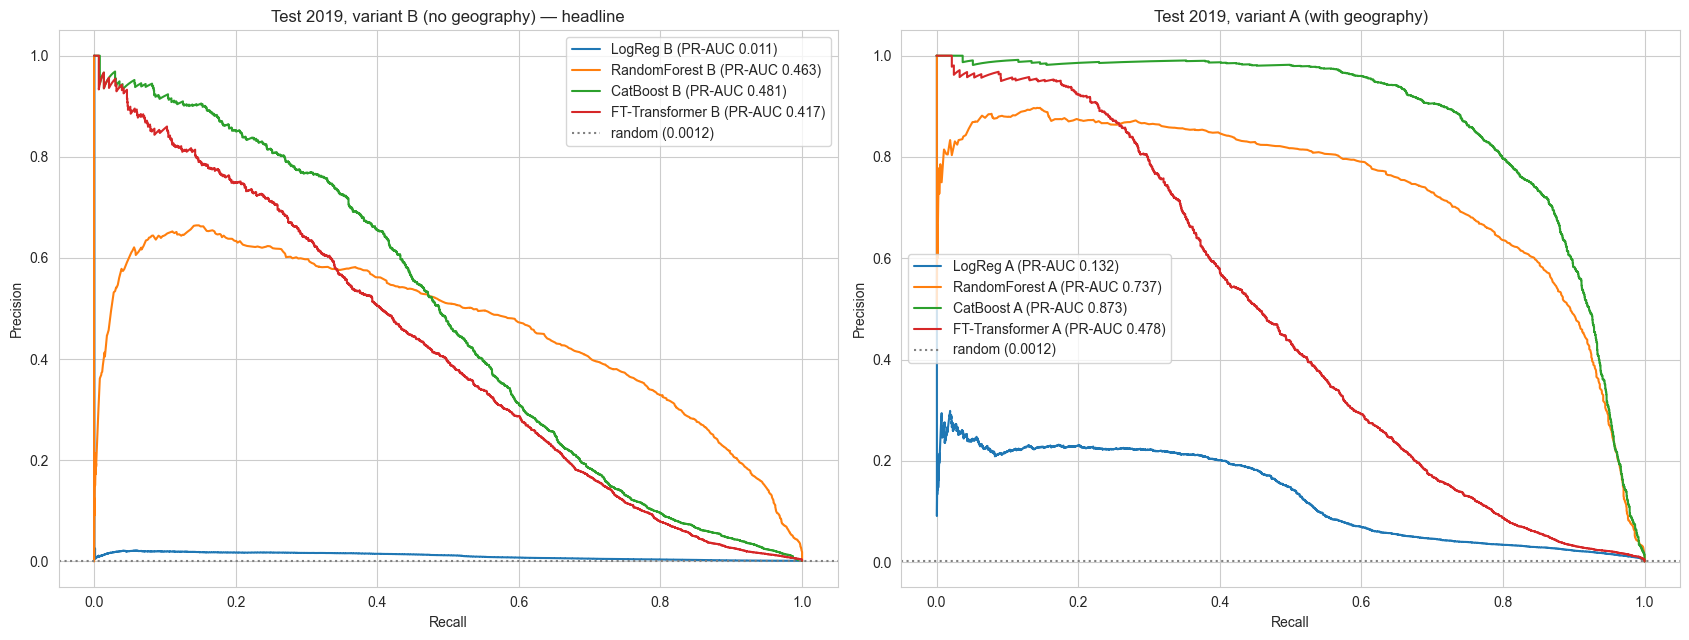

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
plot_pr_curves(y_test, {k: test_scores[k] for k in test_scores if k.endswith(" B")}, ax=axes[0],
               title="Test 2019, variant B (no geography) — headline")
plot_pr_curves(y_test, {k: test_scores[k] for k in test_scores if k.endswith(" A")}, ax=axes[1],
               title="Test 2019, variant A (with geography)")
plt.tight_layout(); fig.savefig(FIG_DIR / "test_pr_curves.png", dpi=120); plt.show()

## 2. Test results by segment

In [6]:
SEGMENTS = ["in-store domestic", "in-store international", "online"]
segment = np.select([test["is_online"] == 1, test["is_international"] == 1], [SEGMENTS[2], SEGMENTS[1]], default=SEGMENTS[0])
rows = []
for k, p in test_scores.items():
    for s in SEGMENTS:
        m = segment == s
        y, ps = y_test[m], p[m]
        flagged = ps >= THRESHOLDS[k]
        tp = int((flagged & (y == 1)).sum())
        rows.append({"model": k, "segment": s, "frauds": int(y.sum()),
                     "pr_auc_within": average_precision_score(y, ps) if y.sum() else np.nan,
                     "alerts@thr": int(flagged.sum()), "recall@thr": tp / max(int(y.sum()), 1),
                     "precision@thr": tp / max(int(flagged.sum()), 1)})
test_segments = pd.DataFrame(rows).set_index(["model", "segment"]).round(4)
test_segments.unstack("segment")[["pr_auc_within", "recall@thr"]]

pr_auc_within                                \
segment          in-store domestic in-store international online   
model                                                              
CatBoost A                     NaN                 0.9791    NaN   
CatBoost B                     NaN                 0.8770    NaN   
FT-Transformer A               NaN                 0.8373    NaN   
FT-Transformer B               NaN                 0.8456    NaN   
LogReg A                       NaN                 0.4277    NaN   
LogReg B                       NaN                 0.4206    NaN   
RandomForest A                 NaN                 0.9362    NaN   
RandomForest B                 NaN                 0.8663    NaN   

                        recall@thr                                
segment          in-store domestic in-store international online  
model                                                             
CatBoost A                     0.0                 0.8146    0.0  
CatBoost B                     0.0                 0.4897    0.0  
FT-Transformer A               0.0                 0.4403    0.0  
FT-Transformer B               0.0                 0.4049    0.0  
LogReg A                       0.0                 0.4413    0.0  
LogReg B                       0.0                 0.0609    0.0  
RandomForest A                 0.0                 0.8083    0.0  
RandomForest B                 0.0                 0.6176    0.0

## 3. SHAP: what drives each model's predictions?

**Sample:** the same 1,000 test transactions for every model: 500 frauds and 500 non-frauds drawn at random. Frauds are over-represented on purpose, so the explanations cover the cases that matter. **Background** (the "typical transaction" each explanation is measured against): 200 random 2018 validation transactions.

| Model | Explainer | Output explained |
|---|---|---|
| Logistic regression | exact linear SHAP; one-hot columns summed back to their feature | log-odds |
| Random Forest | TreeSHAP (path-dependent) | probability |
| CatBoost | CatBoost's built-in TreeSHAP | log-odds |
| FT-Transformer | permutation SHAP on the model's own inputs; missing-value tokens summed back to their feature | log-odds of the 3-seed average |

The units differ, so models are compared by each feature's **share** of the model's total mean |SHAP|.

**Caveats:** SHAP describes what the model uses, not what causes fraud. Credit is split unpredictably among correlated features (for example the amount features).

Main analysis: variant B for all four models. CatBoost A is added to show how the geographic features dominate when they are available.

In [7]:
val = load_split("val", COLS)
fraud_idx = np.flatnonzero(y_test == 1); ok_idx = np.flatnonzero(y_test == 0)
rng = np.random.default_rng(0)
explain_idx = np.concatenate([rng.choice(fraud_idx, 500, replace=False), rng.choice(ok_idx, 500, replace=False)])
X_explain = test.iloc[explain_idx].reset_index(drop=True)
y_explain = y_test[explain_idx]
X_bg = val.sample(200, random_state=0).reset_index(drop=True)

def to_frame(values, names, features):
    """Sum encoded columns back to their source feature."""
    df = pd.DataFrame(values, columns=names)
    return df.T.groupby([source_feature(n, features) if not n.startswith("missing_") else n[len("missing_"):]
                         for n in names]).sum().T[features]

def shap_logreg(b):
    pre, clf = b["preprocessor"], b["model"]
    Xe, Xb = pre.transform(X_explain[b["features"]]), pre.transform(X_bg[b["features"]])
    sv = shap.LinearExplainer(clf, shap.maskers.Independent(Xb)).shap_values(Xe)
    return to_frame(sv, list(pre.get_feature_names_out()), b["features"])

def shap_rf(b):
    from src.modeling import tree_matrix
    sv = shap.TreeExplainer(b["model"]).shap_values(tree_matrix(X_explain, b["features"]), check_additivity=False)
    sv = sv[..., 1] if sv.ndim == 3 else sv[1]
    return pd.DataFrame(sv, columns=b["features"])

def shap_catboost(b):
    from catboost import Pool
    from src.modeling import catboost_frame, categorical_in
    sv = b["model"].get_feature_importance(Pool(catboost_frame(X_explain, b["features"]),
                                                cat_features=categorical_in(b["features"])), type="ShapValues")
    return pd.DataFrame(sv[:, :-1], columns=b["features"])

def shap_ft(b):
    import torch
    from src.ft_transformer import FTTransformer, predict
    pre = b["preprocessor"]
    models = []
    for sd in b["state_dicts"]:
        m = FTTransformer(pre.n_num, pre.cardinalities, **b["model_params"]).cuda(); m.load_state_dict(sd); models.append(m)
    def encode(df):
        xn, xc = pre.transform(df)
        return np.hstack([xn, xc.astype(np.float32)])
    def f(X):
        xn = torch.as_tensor(X[:, :pre.n_num], dtype=torch.float32, device="cuda")
        xc = torch.as_tensor(np.rint(X[:, pre.n_num:]), dtype=torch.int64, device="cuda")
        p = np.mean([predict(m, xn, xc) for m in models], axis=0).clip(1e-7, 1 - 1e-7)
        return np.log(p / (1 - p))
    Xe, Xb = encode(X_explain), encode(X_bg)
    expl = shap.PermutationExplainer(f, shap.maskers.Independent(Xb, max_samples=len(Xb)))
    sv = expl(Xe, max_evals=2 * Xe.shape[1] + 1, batch_size=50, silent=True).values
    return to_frame(sv, pre.num_names + pre.cats, b["features"])

EXPLAINERS = {"LogReg": shap_logreg, "RandomForest": shap_rf, "CatBoost": shap_catboost, "FT-Transformer": shap_ft}
shap_values = {}
for key in [f"{n} B" for n in fm.MODEL_NAMES] + ["CatBoost A"]:
    t0 = time.time()
    shap_values[key] = EXPLAINERS[key.rsplit(" ", 1)[0]](bundles[key])
    print(f"  SHAP {key}: {time.time() - t0:.0f}s")

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


  SHAP LogReg B: 0s


  SHAP RandomForest B: 862s


  SHAP CatBoost B: 1s


  SHAP FT-Transformer B: 304s


  SHAP CatBoost A: 1s


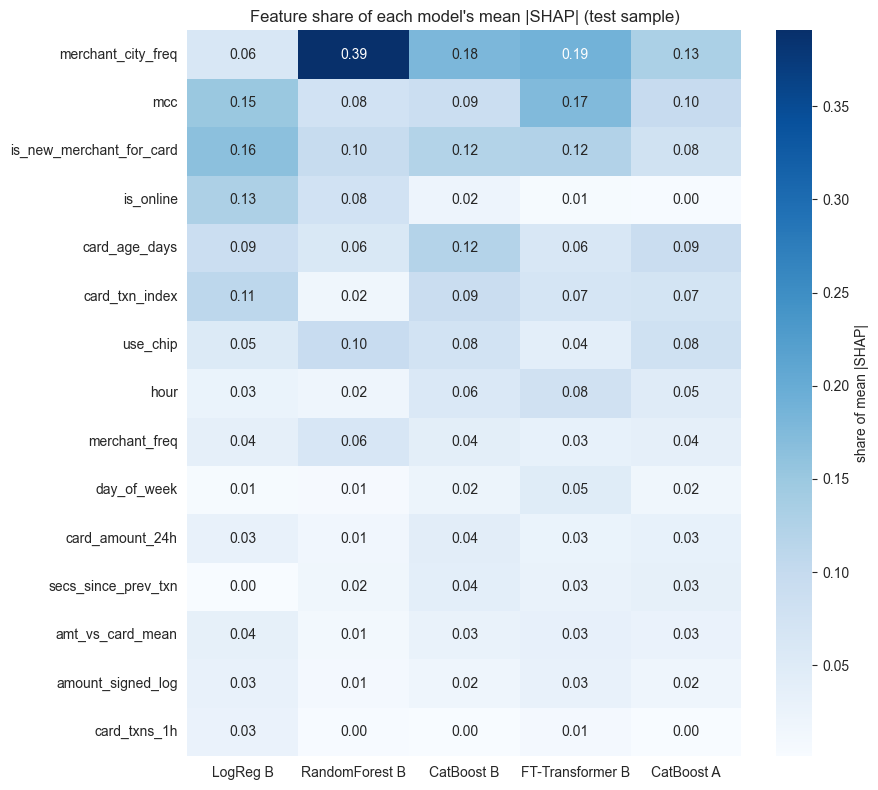

,LogReg B,RandomForest B,CatBoost B,FT-Transformer B,CatBoost A
merchant_city_freq,0.062,0.391,0.179,0.189,0.131
mcc,0.151,0.077,0.089,0.175,0.099
zip_freq,0.000,0.000,0.000,0.000,0.165
is_new_merchant_for_card,0.165,0.096,0.123,0.124,0.078
is_online,0.130,0.076,0.021,0.005,0.004
card_age_days,0.088,0.060,0.120,0.063,0.092
card_txn_index,0.110,0.018,0.092,0.069,0.071
use_chip,0.054,0.095,0.075,0.039,0.080
hour,0.026,0.019,0.058,0.079,0.049
merchant_freq,0.037,0.064,0.042,0.033,0.037


In [8]:
mean_abs = pd.DataFrame({k: v.abs().mean() for k, v in shap_values.items()})
share = (mean_abs / mean_abs.sum()).fillna(0)                     # each model's column sums to 1
top = share[[f"{n} B" for n in fm.MODEL_NAMES]].max(axis=1).sort_values(ascending=False).index[:15]
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(share.loc[top], annot=True, fmt=".2f", cmap="Blues", cbar_kws={"label": "share of mean |SHAP|"}, ax=ax)
ax.set_title("Feature share of each model's mean |SHAP| (test sample)")
plt.tight_layout(); fig.savefig(FIG_DIR / "shap_share_heatmap.png", dpi=120); plt.show()
share.loc[share.max(axis=1).sort_values(ascending=False).index].round(3)

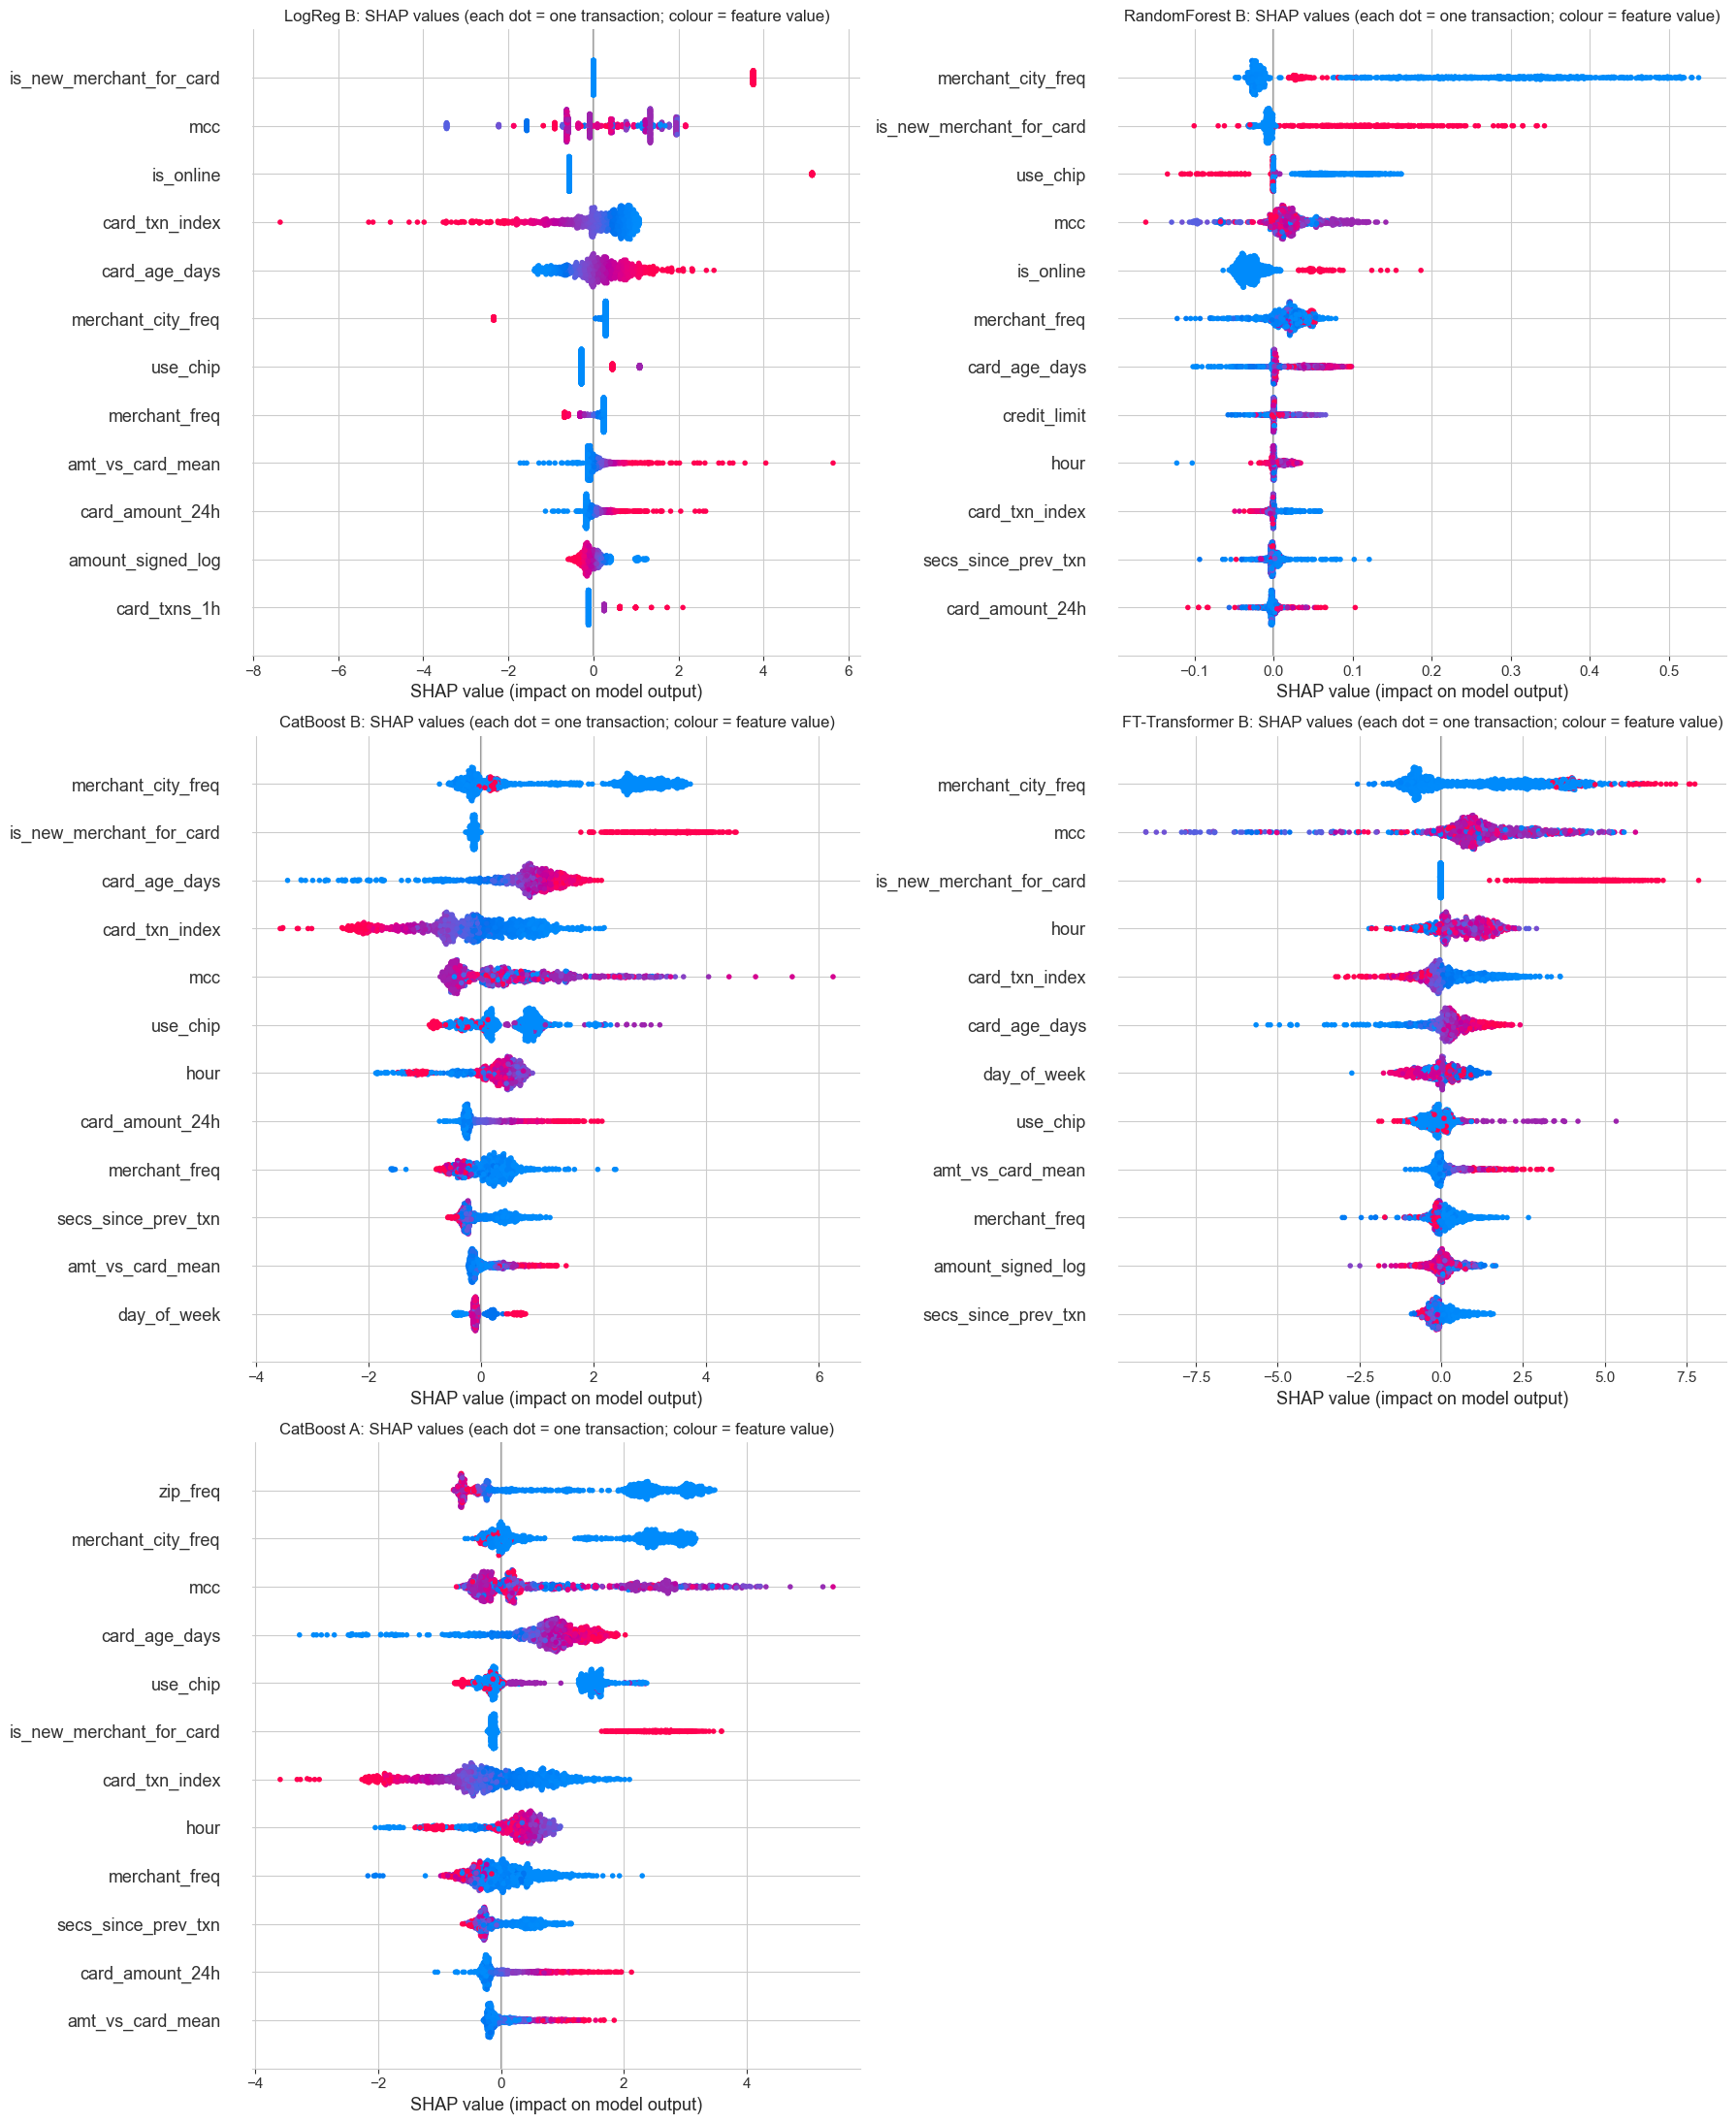

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(18, 22))
for ax, key in zip(axes.flat, shap_values):
    v = shap_values[key]
    plt.sca(ax)
    shap.summary_plot(v.to_numpy(), X_explain[v.columns].apply(lambda c: c.cat.codes if hasattr(c, "cat") else c),
                      feature_names=list(v.columns), max_display=12, show=False, plot_size=None, color_bar=False)
    ax.set_title(f"{key}: SHAP values (each dot = one transaction; colour = feature value)")
axes.flat[-1].axis("off")
plt.tight_layout(); fig.savefig(FIG_DIR / "shap_beeswarms.png", dpi=110); plt.show()

## Findings

*(written after the run)*

## 4. Save

In [10]:
summary.to_csv(REPORTS_DIR / "test_metrics_final.csv")
test_table.to_csv(REPORTS_DIR / "test_metrics_full.csv")
ci.to_csv(REPORTS_DIR / "test_pr_auc_bootstrap_ci.csv")
paired.to_csv(REPORTS_DIR / "test_paired_differences.csv")
test_segments.to_csv(REPORTS_DIR / "test_metrics_by_segment.csv")
share.to_csv(REPORTS_DIR / "shap_importance_share.csv")
print("Saved test metrics, intervals, segments and SHAP importances.")

Saved test metrics, intervals, segments and SHAP importances.
